In [1]:
!pip install -q shap xgboost
import os, json, warnings, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/cdss_data"
RAW   = f"{DRIVE}/raw/uci_heart"
PROC  = f"{DRIVE}/processed/uci_heart"
RES   = f"{DRIVE}/results/cvd"
MODEL_DIR = f"{DRIVE}/processed/models/cvd"
for d in [RAW, PROC, RES, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
np.random.seed(SEED)

Mounted at /content/drive


In [2]:
COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
        "exang", "oldpeak", "slope", "ca", "thal", "num"]
FILES = {"cleveland": "processed.cleveland.data", "hungarian": "processed.hungarian.data",
         "switzerland": "processed.switzerland.data", "va": "processed.va.data"}
URL = "https://archive.ics.uci.edu/static/public/45/heart+disease.zip"


def read_zip(zbytes):
    out = []
    with zipfile.ZipFile(io.BytesIO(zbytes)) as z:
        for src, fn in FILES.items():
            with z.open(fn) as f:
                df = pd.read_csv(f, header=None, names=COLS, na_values=["?", "-9", -9], encoding="latin-1")
            df["source"] = src
            out.append(df)
    return pd.concat(out, ignore_index=True)


def load_uci_heart():
    zpath = f"{RAW}/heart+disease.zip"
    if not os.path.exists(zpath):
        try:
            urllib.request.urlretrieve(URL, zpath)
        except Exception as e:
            print("download failed:", e)
    if os.path.exists(zpath):
        try:
            return read_zip(open(zpath, "rb").read())
        except Exception as e:
            print("could not read zip:", e)
    print("!!! FALLBACK: using only the Cleveland file (303 rows) through ucimlrepo !!!")
    from ucimlrepo import fetch_ucirepo
    r = fetch_ucirepo(id=45)
    df = pd.concat([r.data.features, r.data.targets], axis=1)
    df = df.rename(columns={"class": "num"}) if "class" in df.columns else df
    df["source"] = "cleveland"
    return df[COLS + ["source"]]

In [3]:
raw = load_uci_heart()
print("rows:", len(raw))
print(raw["source"].value_counts().to_string())
raw.head()

rows: 920
source
cleveland      303
hungarian      294
va             200
switzerland    123


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,source
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


In [4]:
df = raw.copy()
n_chol0 = int((df["chol"] == 0).sum()); n_bp0 = int((df["trestbps"] == 0).sum())
df.loc[df["chol"] == 0, "chol"] = np.nan
df.loc[df["trestbps"] == 0, "trestbps"] = np.nan
print(f"cholesterol = 0 turned into NaN: {n_chol0} | resting BP = 0 turned into NaN: {n_bp0}")

df["target"] = (df["num"] > 0).astype(int)
FEATURES = [c for c in COLS if c != "num"]
NUM_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "sex", "fbs", "exang"]
CAT_COLS = ["cp", "restecg", "slope", "thal"]

print("\ndisease present rate:", round(df["target"].mean(), 3))
print("\nmissing % per feature, per hospital:")
miss = df.groupby("source")[FEATURES].apply(lambda g: g.isna().mean() * 100).round(1)
display(miss.T)
miss.T.to_csv(f"{RES}/03_uci_missing_by_source.csv")
df.to_csv(f"{PROC}/uci_heart_clean.csv", index=False)

cholesterol = 0 turned into NaN: 172 | resting BP = 0 turned into NaN: 1

disease present rate: 0.553

missing % per feature, per hospital:


source,cleveland,hungarian,switzerland,va
age,0.0,0.0,0.0,0.0
sex,0.0,0.0,0.0,0.0
cp,0.0,0.0,0.0,0.0
trestbps,0.0,0.3,1.6,28.5
chol,0.0,7.8,100.0,28.0
fbs,0.0,2.7,61.0,3.5
restecg,0.0,0.3,0.8,0.0
thalach,0.0,0.3,0.8,26.5
exang,0.0,0.3,0.8,26.5
oldpeak,0.0,0.0,4.9,28.0


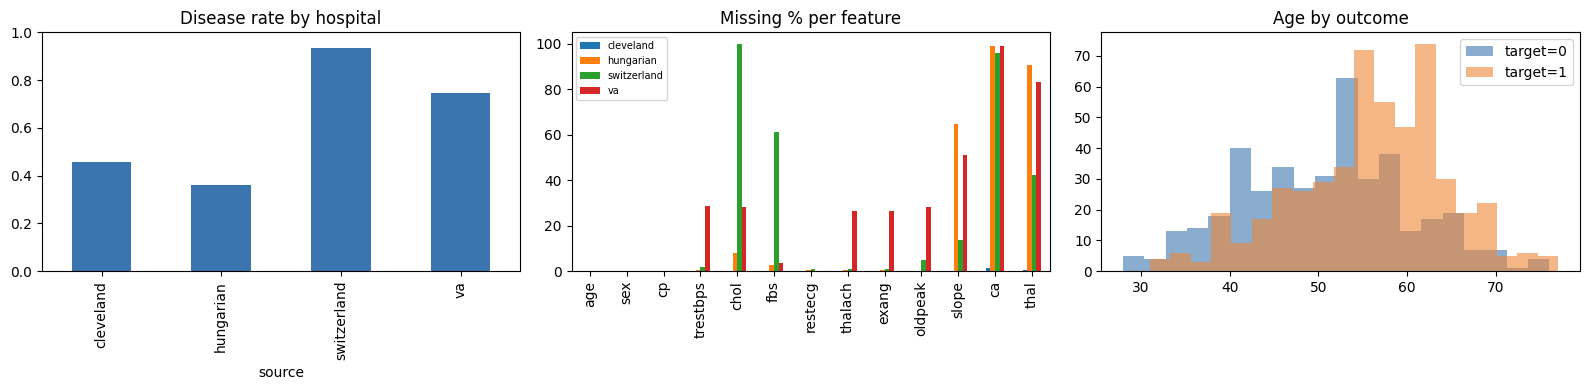

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("source")["target"].agg(["mean", "count"])["mean"].plot.bar(ax=ax[0], color="#3b75af")
ax[0].set_title("Disease rate by hospital"); ax[0].set_ylim(0, 1)
miss.T.plot.bar(ax=ax[1]); ax[1].set_title("Missing % per feature"); ax[1].legend(fontsize=7)
for t, c in [(0, "#3b75af"), (1, "#ef8636")]:
    ax[2].hist(df[df.target == t]["age"].dropna(), bins=20, alpha=.6, color=c, label=f"target={t}")
ax[2].set_title("Age by outcome"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{RES}/03_uci_eda.png", dpi=150); plt.show()

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, brier_score_loss)
from xgboost import XGBClassifier


def make_prep():
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                    ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)])


def get_models():
    return {
        "LogReg": Pipeline([("prep", make_prep()),
                            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "RandomForest": Pipeline([("prep", make_prep()),
                                  ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                                 class_weight="balanced", random_state=SEED, n_jobs=-1))]),
        "XGBoost": Pipeline([("prep", make_prep()),
                             ("clf", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                                   subsample=0.8, colsample_bytree=0.8,
                                                   eval_metric="logloss", random_state=SEED))]),
    }


strat = df["source"] + "_" + df["target"].astype(str)
tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=strat)
Xtr, ytr = df.iloc[tr_idx][FEATURES], df.iloc[tr_idx]["target"]
Xte, yte = df.iloc[te_idx][FEATURES], df.iloc[te_idx]["target"]
print("train:", len(Xtr), "| test:", len(Xte), "| test disease rate:", round(yte.mean(), 3))

train: 736 | test: 184 | test disease rate: 0.554


In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"auroc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}

cv_rows = []
for name, m in get_models().items():
    s = cross_validate(m, Xtr, ytr, cv=cv, scoring=scoring)
    cv_rows.append({"model": name, **{k: f"{s[f'test_{k}'].mean():.3f} ± {s[f'test_{k}'].std():.3f}" for k in scoring}})
cv_table = pd.DataFrame(cv_rows).set_index("model")
print("5-fold cross-validation on the training split (mean ± std):")
display(cv_table)
cv_table.to_csv(f"{RES}/03_uci_cv_results.csv")

5-fold cross-validation on the training split (mean ± std):


,auroc,f1,precision,recall,accuracy
model,,,,,
LogReg,0.896 ± 0.021,0.835 ± 0.038,0.854 ± 0.032,0.820 ± 0.069,0.822 ± 0.033
RandomForest,0.891 ± 0.023,0.827 ± 0.022,0.833 ± 0.042,0.828 ± 0.060,0.810 ± 0.020
XGBoost,0.885 ± 0.018,0.826 ± 0.030,0.821 ± 0.029,0.835 ± 0.059,0.807 ± 0.028


In [8]:
# Final fit on the full training split, one evaluation on the held-out test split
models, test_prob, rows = {}, {}, []
for name, m in get_models().items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    pred = (p >= 0.5).astype(int)
    models[name], test_prob[name] = m, p
    rows.append({"model": name, "auroc": roc_auc_score(yte, p), "f1": f1_score(yte, pred),
                 "precision": precision_score(yte, pred), "recall": recall_score(yte, pred),
                 "accuracy": accuracy_score(yte, pred), "brier": brier_score_loss(yte, p)})
test_table = pd.DataFrame(rows).set_index("model").round(3)
print("held-out test split:")
display(test_table)
test_table.to_csv(f"{RES}/03_uci_test_results.csv")
BEST = test_table["auroc"].idxmax()
print("best model on test AUROC:", BEST)

held-out test split:


,auroc,f1,precision,recall,accuracy,brier
model,,,,,,
LogReg,0.903,0.856,0.840,0.873,0.837,0.120
RandomForest,0.887,0.861,0.841,0.882,0.842,0.133
XGBoost,0.887,0.845,0.811,0.882,0.821,0.134


best model on test AUROC: LogReg


In [9]:
loho_rows = []
for held in df["source"].unique():
    trm = df["source"] != held
    for name, m in get_models().items():
        m.fit(df[trm][FEATURES], df[trm]["target"])
        te_sub = df[~trm]
        p = m.predict_proba(te_sub[FEATURES])[:, 1]
        auc = roc_auc_score(te_sub["target"], p) if te_sub["target"].nunique() == 2 else np.nan
        loho_rows.append({"held_out": held, "n": len(te_sub), "model": name, "auroc": round(auc, 3)})
loho = pd.DataFrame(loho_rows).pivot(index=["held_out", "n"], columns="model", values="auroc")
display(loho)
loho.to_csv(f"{RES}/03_uci_leave_one_hospital_out.csv")

,model,LogReg,RandomForest,XGBoost
held_out,n,,,
cleveland,303,0.867,0.857,0.857
hungarian,294,0.898,0.869,0.856
switzerland,123,0.748,0.776,0.762
va,200,0.722,0.718,0.687


,LogReg,RandomForest,XGBoost
inputs hidden,,,
0%,0.903,0.887,0.887
10%,0.877,0.875,0.878
20%,0.840,0.855,0.859
30%,0.815,0.846,0.851
40%,0.763,0.804,0.812
50%,0.729,0.791,0.795
60%,0.698,0.727,0.761


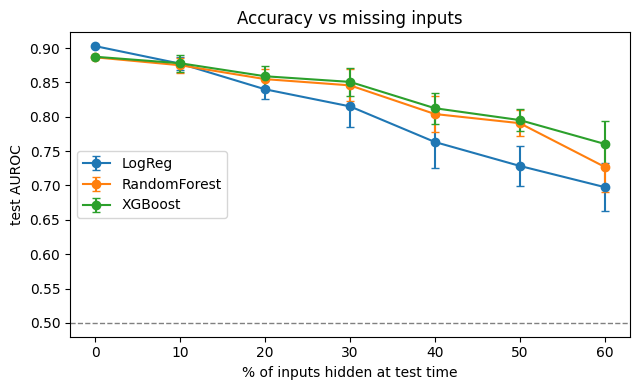

In [10]:
rng = np.random.default_rng(SEED)
levels = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
robust = {n: [] for n in models}
robust_sd = {n: [] for n in models}
for frac in levels:
    aucs = {n: [] for n in models}
    for rep in range(10 if frac > 0 else 1):
        Xm = Xte.copy().astype(float)
        mask = rng.random(Xm.shape) < frac
        Xm = Xm.mask(mask)
        for n, m in models.items():
            aucs[n].append(roc_auc_score(yte, m.predict_proba(Xm)[:, 1]))
    for n in models:
        robust[n].append(np.mean(aucs[n])); robust_sd[n].append(np.std(aucs[n]))

rob = pd.DataFrame(robust, index=[f"{int(l*100)}%" for l in levels]).round(3)
rob.index.name = "inputs hidden"
display(rob)
rob.to_csv(f"{RES}/03_uci_missing_data_robustness.csv")

plt.figure(figsize=(6.5, 4))
for n in models:
    plt.errorbar([l * 100 for l in levels], robust[n], yerr=robust_sd[n], marker="o", label=n, capsize=3)
plt.axhline(0.5, color="grey", ls="--", lw=1)
plt.xlabel("% of inputs hidden at test time"); plt.ylabel("test AUROC")
plt.title("Accuracy vs missing inputs"); plt.legend(); plt.tight_layout()
plt.savefig(f"{RES}/03_uci_missing_robustness.png", dpi=150); plt.show()

LogReg: Brier raw = 0.120 | calibrated = 0.121
LogReg: AUROC raw = 0.903 | calibrated = 0.903


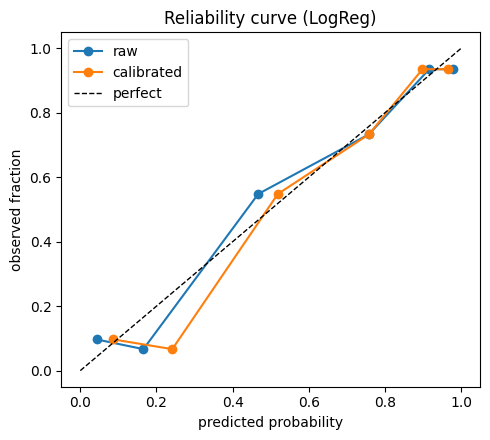

In [11]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.base import clone

cal = CalibratedClassifierCV(clone(models[BEST]), method="sigmoid", cv=5).fit(Xtr, ytr)
p_raw = test_prob[BEST]
p_cal = cal.predict_proba(Xte)[:, 1]
print(f"{BEST}: Brier raw = {brier_score_loss(yte, p_raw):.3f} | calibrated = {brier_score_loss(yte, p_cal):.3f}")
print(f"{BEST}: AUROC raw = {roc_auc_score(yte, p_raw):.3f} | calibrated = {roc_auc_score(yte, p_cal):.3f}")

plt.figure(figsize=(5, 4.5))
for lab, p in [("raw", p_raw), ("calibrated", p_cal)]:
    fr, mp = calibration_curve(yte, p, n_bins=6, strategy="quantile")
    plt.plot(mp, fr, marker="o", label=lab)
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
plt.xlabel("predicted probability"); plt.ylabel("observed fraction")
plt.title(f"Reliability curve ({BEST})"); plt.legend(); plt.tight_layout()
plt.savefig(f"{RES}/03_uci_calibration.png", dpi=150); plt.show()

SHAP explainer initialized for BEST model: LogReg | SHAP matrix shape: (184, 29)


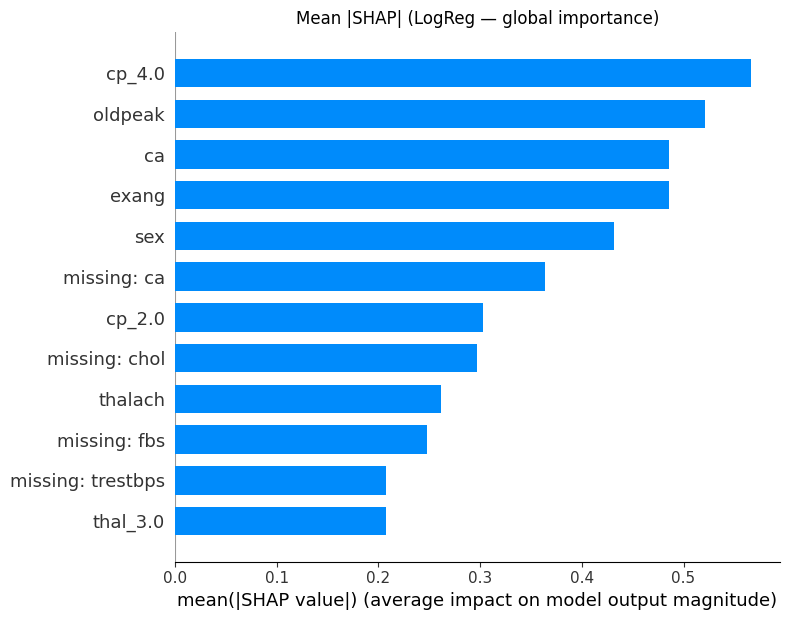

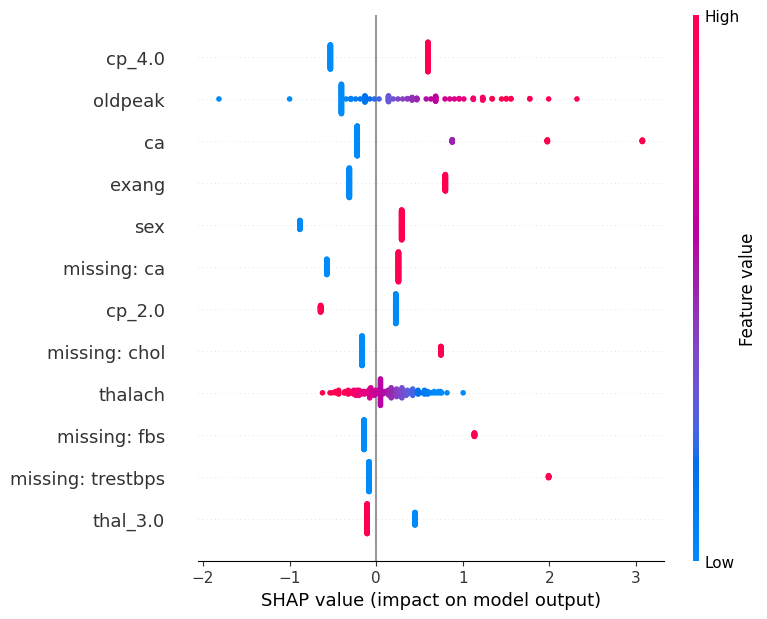

In [12]:
import shap

# Explain the exact model family selected as BEST (no predictor-explainer mismatch)
best_pipe = models[BEST]
prep, clf = best_pipe.named_steps["prep"], best_pipe.named_steps["clf"]
feat_names = [n.replace("num__imp__", "").replace("num__", "").replace("cat__", "")
              for n in prep.get_feature_names_out()]
feat_names = [n.replace("missingindicator_", "missing: ") for n in feat_names]

Xtr_t = prep.transform(Xtr)
Xtr_t = Xtr_t.toarray() if hasattr(Xtr_t, "toarray") else np.asarray(Xtr_t)
Xte_t = prep.transform(Xte)
Xte_t = Xte_t.toarray() if hasattr(Xte_t, "toarray") else np.asarray(Xte_t)

if BEST in ("XGBoost", "RandomForest"):
    explainer = shap.TreeExplainer(clf)
    raw_sv = explainer.shap_values(Xte_t)
    # RandomForest returns (N, F, 2) or list of 2 arrays; extract class-1 SHAP values
    if isinstance(raw_sv, list):
        sv = raw_sv[1]
        base_val = explainer.expected_value[1]
    elif raw_sv.ndim == 3:
        sv = raw_sv[:, :, 1]
        base_val = explainer.expected_value[1]
    else:
        sv = raw_sv
        base_val = explainer.expected_value
else:  # LogReg
    explainer = shap.LinearExplainer(clf, Xtr_t)
    sv = explainer.shap_values(Xte_t)
    base_val = explainer.expected_value

print(f"SHAP explainer initialized for BEST model: {BEST} | SHAP matrix shape: {sv.shape}")

plt.figure()
shap.summary_plot(sv, Xte_t, feature_names=feat_names, plot_type="bar", show=False, max_display=12)
plt.title(f"Mean |SHAP| ({BEST} — global importance)"); plt.tight_layout()
plt.savefig(f"{RES}/03_uci_shap_global_bar.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure()
shap.summary_plot(sv, Xte_t, feature_names=feat_names, show=False, max_display=12)
plt.tight_layout(); plt.savefig(f"{RES}/03_uci_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

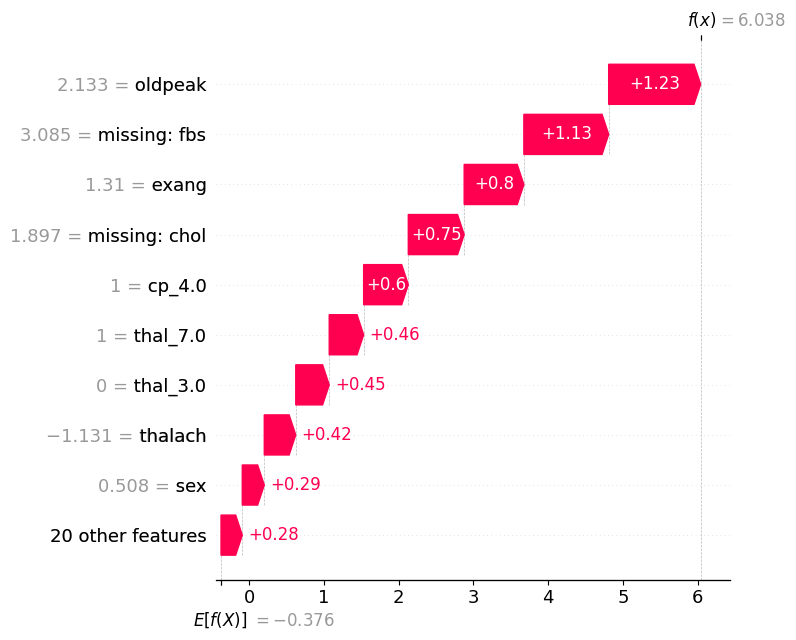

true label: 1 | calibrated probability: 0.994
age          54.0
sex           1.0
cp            4.0
trestbps    130.0
chol          NaN
fbs           NaN
restecg       0.0
thalach     110.0
exang         1.0
oldpeak       3.0
slope         2.0
ca            NaN
thal          7.0


In [13]:
i = int(np.argmax(p_cal))
exp = shap.Explanation(values=sv[i], base_values=base_val, data=Xte_t[i], feature_names=feat_names)
plt.figure(); shap.plots.waterfall(exp, max_display=10, show=False)
plt.tight_layout(); plt.savefig(f"{RES}/03_uci_shap_patient.png", dpi=150, bbox_inches="tight"); plt.show()
print("true label:", int(yte.iloc[i]), "| calibrated probability:", round(float(p_cal[i]), 3))
print(Xte.iloc[i].to_string())

In [14]:
final_model = cal  # calibrated best model, used for risk
joblib.dump({
    "model": final_model,
    "raw_models": models,
    "features": FEATURES,
    "best": BEST,
    "Xtr_background": Xtr_t[:100],  # needed if BEST == "LogReg" for LinearExplainer
}, f"{MODEL_DIR}/uci_heart_models.joblib")

np.savez(f"{RES}/03_uci_test_predictions.npz", idx=te_idx, y=yte.values,
         **{f"p_{k}": v for k, v in test_prob.items()}, p_calibrated=p_cal)


def get_single_shap(row_df):
    xt = prep.transform(row_df[FEATURES])
    xt = xt.toarray() if hasattr(xt, "toarray") else np.asarray(xt)
    raw_s = explainer.shap_values(xt)
    if isinstance(raw_s, list):
        return raw_s[1][0]
    if raw_s.ndim == 3:
        return raw_s[0, :, 1]
    return raw_s[0]


def explain_row(row_df, top_k=5):
    """Risk and top SHAP contributions aligned with the shared API contract."""
    risk = float(final_model.predict_proba(row_df[FEATURES])[:, 1][0])
    s = get_single_shap(row_df)
    order = np.argsort(-np.abs(s))[:top_k]
    return {
        "disease": "cvd",
        "risk": round(risk, 3),
        "missing_inputs": [c for c in FEATURES if pd.isna(row_df[c].iloc[0])],
        "explanation": [{"feature": feat_names[j], "shap": round(float(s[j]), 3),
                         "direction": "raises risk" if s[j] > 0 else "lowers risk"} for j in order],
    }


example = explain_row(Xte.iloc[[i]])
json.dump(example, open(f"{RES}/03_uci_example_api_block.json", "w"), indent=2)
print(json.dumps(example, indent=2))

{
  "disease": "cvd",
  "risk": 0.994,
  "missing_inputs": [
    "chol",
    "fbs",
    "ca"
  ],
  "explanation": [
    {
      "feature": "oldpeak",
      "shap": 1.23,
      "direction": "raises risk"
    },
    {
      "feature": "missing: fbs",
      "shap": 1.134,
      "direction": "raises risk"
    },
    {
      "feature": "exang",
      "shap": 0.798,
      "direction": "raises risk"
    },
    {
      "feature": "missing: chol",
      "shap": 0.747,
      "direction": "raises risk"
    },
    {
      "feature": "cp_4.0",
      "shap": 0.597,
      "direction": "raises risk"
    }
  ]
}
